
# Customer Churn Prediction Project

## Objective
Predict customer churn using:
- Customer profile data
- Support interactions
- Broadband usage
- Payment behavior

## Business Goal
Help retention teams identify high-risk customers before churn occurs.


In [38]:

# ============================================================
# IMPORT LIBRARIES
# ============================================================

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")


In [39]:
# ============================================================
# DATABASE CONNECTION
# ============================================================

# Using in-memory DuckDB database
# avoids file locking issues

con = duckdb.connect(database=":memory:")

In [40]:

# ============================================================
# LOAD DATASETS
# ============================================================

con.sql(
    "CREATE OR REPLACE TABLE cease AS SELECT * FROM 'cease.csv'"
)

con.sql(
    "CREATE OR REPLACE TABLE customer_info AS SELECT * FROM 'customer_info.csv'"
)

con.sql(
    "CREATE OR REPLACE TABLE calls AS SELECT * FROM 'calls.csv'"
)

con.sql(
    "CREATE OR REPLACE TABLE usage AS SELECT * FROM 'usage.parquet'"
)


print("Datasets loaded successfully.")


Datasets loaded successfully.


In [41]:

# ============================================================
# TARGET VARIABLE CREATION
# ============================================================

target_df = con.sql(
    '''
    SELECT DISTINCT
        unique_customer_identifier,
        1 AS target
    FROM cease
    '''
).df()

target_df.head()


,unique_customer_identifier,target
0,20b4d67a35baf224e44f545d299662794daecd8ff8c686...,1
1,d242f0ccbb29c590297544793bdd2e3ec16cfdf8711a6b...,1
2,582ff8782c5a49e539da3b0a2acc2e2d1e81e70d8ae46a...,1
3,9bc1fc87a16a12be6ccee29f68d80d98dc63d793230f4a...,1
4,88ae1078c78559d84d5e06d7bb2cb4961679eb7e56de51...,1


In [42]:

# ============================================================
# CUSTOMER FEATURE EXTRACTION
# ============================================================

customer_df = con.sql(
    '''
    SELECT
        unique_customer_identifier,
        contract_status,
        contract_dd_cancels,
        dd_cancel_60_day,
        ooc_days,
        technology,
        speed,
        line_speed,
        sales_channel,
        crm_package_name,
        tenure_days
    FROM customer_info
    '''
).df()

customer_df.head()


,unique_customer_identifier,contract_status,contract_dd_cancels,dd_cancel_60_day,ooc_days,technology,speed,line_speed,sales_channel,crm_package_name,tenure_days
0,301fc0009efabaa62b7d293773a50893eb039b0c86e033...,01 Early Contract,0,0,-691,FTTC,65,74.851000,Unknown,Fibre 65 (FTTC-OR),5281
1,7ccb2a1beb40d3e3c02c8e1e0a1b7078802a005399a4b5...,02 In Contract,0,0,-426,FTTC,65,79.004000,Migrated Customer,Fibre 65 (FTTC-OR),5291
2,d4ce397a010cebf469dd7bced0af7e600d0a1191228ddd...,06 OOC,0,0,5216,MPF,18,15.825229,Migrated Customer,Broadband Only (SMPF),5765
3,c28defb617d769c0d1dbd5da416c533f6608d5813b8620...,02 In Contract,0,0,-448,FTTC,65,63.818000,Unknown,Fibre 65 (FTTC-OR),5331
4,dca599e0a768bf41fc09e398fd249d395183b71c78729b...,02 In Contract,0,0,-535,FTTC,65,52.445000,Online - Search,Fibre 65 (FTTC-OR),4496


In [43]:

# ============================================================
# CUSTOMER SUPPORT FEATURES
# ============================================================

call_df = con.sql(
    '''
    SELECT
        unique_customer_identifier,
        COUNT(*) AS total_calls,
        SUM(talk_time_seconds) AS total_talk_time,
        SUM(hold_time_seconds) AS total_hold_time
    FROM calls
    GROUP BY unique_customer_identifier
    '''
).df()

call_df.head()


,unique_customer_identifier,total_calls,total_talk_time,total_hold_time
0,67f811fa5dae31e4c96ecf1931f9163fe73735e32f78a3...,9,7853.0,2361.0
1,a8a87ecac2f96e01910faf543238891017a6f005ed5efa...,11,6378.0,988.0
2,3bd353ee161bae3557a7770d90e3f80e0b931f319bb81b...,2,1520.0,0.0
3,06637da54c9cf99f516be76e2d91ceb773c1c200bf6ee0...,10,5220.0,1353.0
4,66cd9a668926fe537e7f5f61c326a30372ec4cc56600ee...,28,11732.0,3830.0


In [44]:

# ============================================================
# BROADBAND USAGE FEATURES
# ============================================================

usage_df = con.sql(
    '''
    SELECT
        unique_customer_identifier,

        AVG(CAST(usage_download_mbs AS DOUBLE))
            AS avg_download_usage,

        AVG(CAST(usage_upload_mbs AS DOUBLE))
            AS avg_upload_usage

    FROM usage

    GROUP BY unique_customer_identifier
    '''
).df()

usage_df.head()


,unique_customer_identifier,avg_download_usage,avg_upload_usage
0,a579a450db6580b255d01ea726bc611319ccf11a819db5...,1449.710678,104.596496
1,ef186cc7baac53d7e4c1118686c6428cbcba409b282c55...,272.441825,17.510692
2,41a94b044d068680e873c546af2d7f1070605d68d18165...,1922.053264,179.242414
3,a2538d6328b1e2442cfc73bf048a1f82996c2fb7d67125...,10352.800329,953.170765
4,8e9524d9b0f9435b024e2afcaeb625153549e692a9bdbf...,11394.393115,413.450729


In [45]:

# ============================================================
# MERGE DATASETS
# ============================================================

df = customer_df.merge(
    target_df,
    on="unique_customer_identifier",
    how="left"
)

df = df.merge(
    call_df,
    on="unique_customer_identifier",
    how="left"
)

df = df.merge(
    usage_df,
    on="unique_customer_identifier",
    how="left"
)

df["target"] = df["target"].fillna(0)

df.head()


,unique_customer_identifier,contract_status,contract_dd_cancels,dd_cancel_60_day,ooc_days,technology,speed,line_speed,sales_channel,crm_package_name,tenure_days,target,total_calls,total_talk_time,total_hold_time,avg_download_usage,avg_upload_usage
0,301fc0009efabaa62b7d293773a50893eb039b0c86e033...,01 Early Contract,0,0,-691,FTTC,65,74.851000,Unknown,Fibre 65 (FTTC-OR),5281,0.0,1.0,170.0,0.0,4840.502774,85.509457
1,7ccb2a1beb40d3e3c02c8e1e0a1b7078802a005399a4b5...,02 In Contract,0,0,-426,FTTC,65,79.004000,Migrated Customer,Fibre 65 (FTTC-OR),5291,0.0,NaN,NaN,NaN,11548.578607,585.130679
2,d4ce397a010cebf469dd7bced0af7e600d0a1191228ddd...,06 OOC,0,0,5216,MPF,18,15.825229,Migrated Customer,Broadband Only (SMPF),5765,1.0,5.0,2138.0,81.0,7736.329490,318.390270
3,c28defb617d769c0d1dbd5da416c533f6608d5813b8620...,02 In Contract,0,0,-448,FTTC,65,63.818000,Unknown,Fibre 65 (FTTC-OR),5331,0.0,1.0,2196.0,0.0,11088.839122,694.712772
4,dca599e0a768bf41fc09e398fd249d395183b71c78729b...,02 In Contract,0,0,-535,FTTC,65,52.445000,Online - Search,Fibre 65 (FTTC-OR),4496,0.0,NaN,NaN,NaN,10560.529091,473.770109


In [46]:

# ============================================================
# DATA CLEANING
# ============================================================

numeric_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns

df[numeric_cols] = df[numeric_cols].fillna(0)

categorical_cols = df.select_dtypes(
    include=["object"]
).columns

df[categorical_cols] = df[categorical_cols].fillna("Unknown")

print("Numeric Columns:")
print(numeric_cols)

print("\nCategorical Columns:")
print(categorical_cols)


Numeric Columns:
Index(['contract_dd_cancels', 'dd_cancel_60_day', 'speed', 'line_speed',
       'tenure_days', 'target', 'total_calls', 'total_talk_time',
       'total_hold_time', 'avg_download_usage', 'avg_upload_usage'],
      dtype='object')

Categorical Columns:
Index(['unique_customer_identifier', 'contract_status', 'ooc_days',
       'technology', 'sales_channel', 'crm_package_name'],
      dtype='object')


In [47]:

# ============================================================
# DATA TYPE CONVERSION
# ============================================================

df["ooc_days"] = pd.to_numeric(
    df["ooc_days"],
    errors="coerce"
)

df["dd_cancel_60_day"] = pd.to_numeric(
    df["dd_cancel_60_day"],
    errors="coerce"
)

df["speed"] = pd.to_numeric(
    df["speed"],
    errors="coerce"
)

df["line_speed"] = pd.to_numeric(
    df["line_speed"],
    errors="coerce"
)

print("Data type conversion completed.")


Data type conversion completed.


In [48]:

# ============================================================
# FEATURE ENGINEERING
# ============================================================

df["is_out_of_contract"] = np.where(
    df["ooc_days"] > 0,
    1,
    0
)

df["high_dd_cancel"] = np.where(
    df["dd_cancel_60_day"] > 1,
    1,
    0
)

df["speed_gap"] = df["speed"] - df["line_speed"]

df.head()


,unique_customer_identifier,contract_status,contract_dd_cancels,dd_cancel_60_day,ooc_days,technology,speed,line_speed,sales_channel,crm_package_name,tenure_days,target,total_calls,total_talk_time,total_hold_time,avg_download_usage,avg_upload_usage,is_out_of_contract,high_dd_cancel,speed_gap
0,301fc0009efabaa62b7d293773a50893eb039b0c86e033...,01 Early Contract,0,0,-691.0,FTTC,65,74.851000,Unknown,Fibre 65 (FTTC-OR),5281,0.0,1.0,170.0,0.0,4840.502774,85.509457,0,0,-9.851000
1,7ccb2a1beb40d3e3c02c8e1e0a1b7078802a005399a4b5...,02 In Contract,0,0,-426.0,FTTC,65,79.004000,Migrated Customer,Fibre 65 (FTTC-OR),5291,0.0,0.0,0.0,0.0,11548.578607,585.130679,0,0,-14.004000
2,d4ce397a010cebf469dd7bced0af7e600d0a1191228ddd...,06 OOC,0,0,5216.0,MPF,18,15.825229,Migrated Customer,Broadband Only (SMPF),5765,1.0,5.0,2138.0,81.0,7736.329490,318.390270,1,0,2.174771
3,c28defb617d769c0d1dbd5da416c533f6608d5813b8620...,02 In Contract,0,0,-448.0,FTTC,65,63.818000,Unknown,Fibre 65 (FTTC-OR),5331,0.0,1.0,2196.0,0.0,11088.839122,694.712772,0,0,1.182000
4,dca599e0a768bf41fc09e398fd249d395183b71c78729b...,02 In Contract,0,0,-535.0,FTTC,65,52.445000,Online - Search,Fibre 65 (FTTC-OR),4496,0.0,0.0,0.0,0.0,10560.529091,473.770109,0,0,12.555000


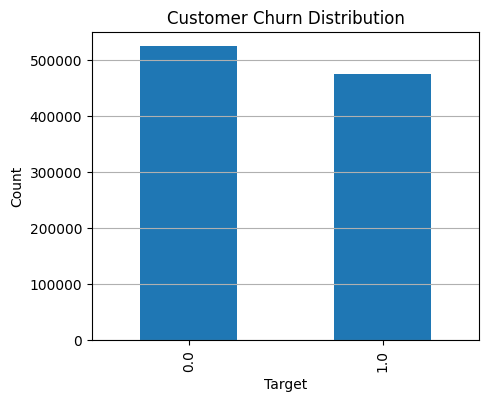

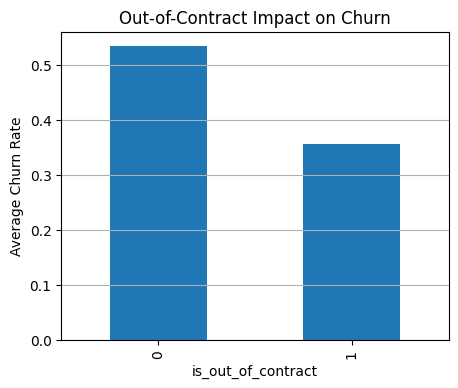

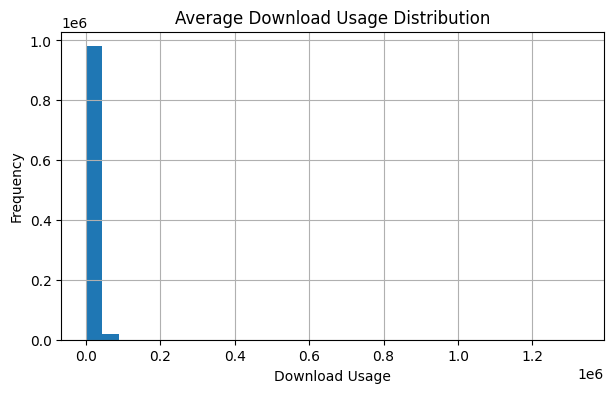

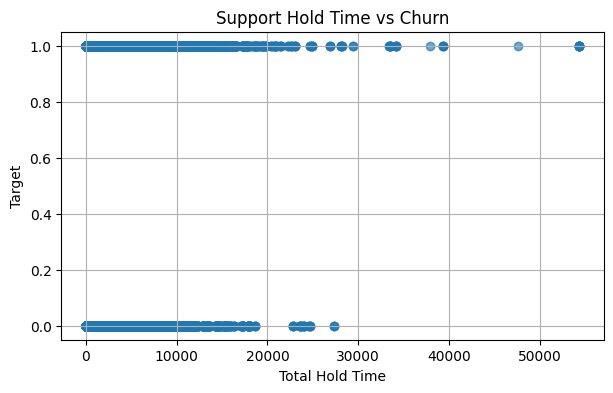

In [49]:

# ============================================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Churn Distribution
plt.figure(figsize=(5,4))
df["target"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.grid(axis="y")
plt.show()

# Out-of-Contract Impact
plt.figure(figsize=(5,4))
df.groupby("is_out_of_contract")["target"].mean().plot(kind="bar")
plt.title("Out-of-Contract Impact on Churn")
plt.ylabel("Average Churn Rate")
plt.grid(axis="y")
plt.show()

# Broadband Usage Distribution
plt.figure(figsize=(7,4))
plt.hist(df["avg_download_usage"], bins=30)
plt.title("Average Download Usage Distribution")
plt.xlabel("Download Usage")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

# Hold Time vs Churn
plt.figure(figsize=(7,4))
plt.scatter(df["total_hold_time"], df["target"], alpha=0.4)
plt.title("Support Hold Time vs Churn")
plt.xlabel("Total Hold Time")
plt.ylabel("Target")
plt.grid(True)
plt.show()


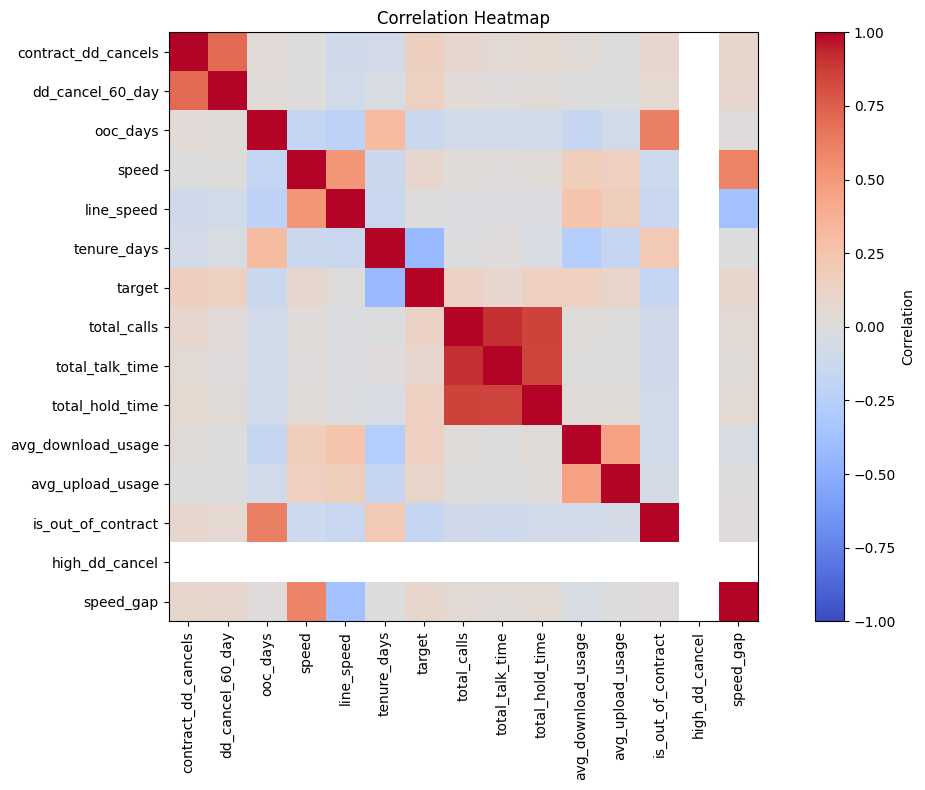

In [50]:

# ============================================================
# CORRELATION HEATMAP
# ============================================================

corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12,8))

plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()


In [51]:

# ============================================================
# ENCODE CATEGORICAL VARIABLES
# ============================================================

encoder = LabelEncoder()

for col in categorical_cols:

    if col != "unique_customer_identifier":

        df[col] = encoder.fit_transform(df[col])

print("Categorical encoding completed.")


Categorical encoding completed.


In [52]:

# ============================================================
# PREPARE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=["target"])

y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (800000, 19)
Testing Data Shape: (200000, 19)


In [53]:
# ============================================================
# PREPARE FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=[
        "target",
        "unique_customer_identifier"
    ]
)

y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (800000, 18)
Testing Data Shape: (200000, 18)


In [54]:
# ============================================================
# RANDOM FOREST MODEL
# ============================================================

model = RandomForestClassifier(
    n_estimators=50,
    max_depth=8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Prediction probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("\nRANDOM FOREST RESULTS")

print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))


RANDOM FOREST RESULTS
              precision    recall  f1-score   support

         0.0       0.80      0.73      0.77    104940
         1.0       0.73      0.80      0.76     95060

    accuracy                           0.76    200000
   macro avg       0.77      0.77      0.76    200000
weighted avg       0.77      0.76      0.76    200000

ROC-AUC: 0.8442134834665125


In [55]:
# ============================================================
# LOGISTIC REGRESSION MODEL
# ============================================================

log_model = LogisticRegression(max_iter=1000)

# Train model
log_model.fit(X_train, y_train)

# Predictions
log_pred = log_model.predict(X_test)

# Prediction probabilities
log_prob = log_model.predict_proba(X_test)[:, 1]

print("\nLOGISTIC REGRESSION RESULTS")

print(classification_report(y_test, log_pred))

print("ROC-AUC:", roc_auc_score(y_test, log_prob))


LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

         0.0       0.75      0.71      0.73    104940
         1.0       0.70      0.74      0.72     95060

    accuracy                           0.73    200000
   macro avg       0.73      0.73      0.73    200000
weighted avg       0.73      0.73      0.73    200000

ROC-AUC: 0.7878786072379592


In [56]:

# ============================================================
# MODEL EVALUATION
# ============================================================

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("\nRANDOM FOREST RESULTS")
print(classification_report(y_test, y_pred))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC SCORE")
print(roc_auc_score(y_test, y_prob))



RANDOM FOREST RESULTS
              precision    recall  f1-score   support

         0.0       0.80      0.73      0.77    104940
         1.0       0.73      0.80      0.76     95060

    accuracy                           0.76    200000
   macro avg       0.77      0.77      0.76    200000
weighted avg       0.77      0.76      0.76    200000


CONFUSION MATRIX
[[77018 27922]
 [19184 75876]]

ROC-AUC SCORE
0.8442134834665125


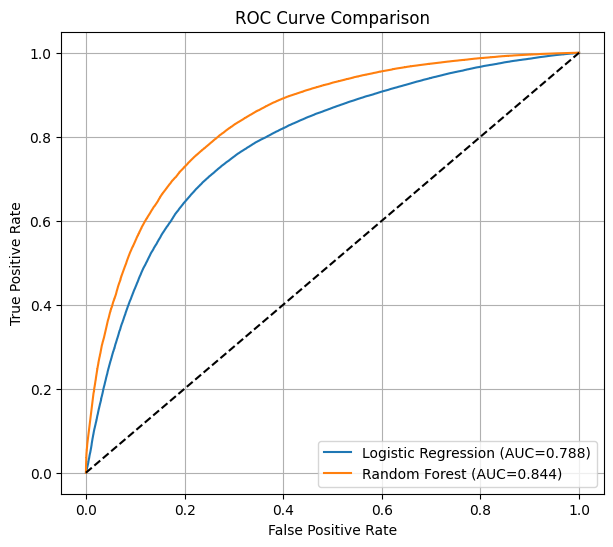

In [57]:

# ============================================================
# ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(7,6))

fpr_log, tpr_log, _ = roc_curve(y_test, log_prob)
auc_log = roc_auc_score(y_test, log_prob)

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC={auc_log:.3f})"
)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob)
auc_rf = roc_auc_score(y_test, y_prob)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC={auc_rf:.3f})"
)

plt.plot([0,1], [0,1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(True)

plt.show()



TOP 10 FEATURES
                Feature  Importance
9           tenure_days    0.373865
7         sales_channel    0.110280
11      total_talk_time    0.084025
10          total_calls    0.078009
12      total_hold_time    0.058703
3              ooc_days    0.058042
0       contract_status    0.039006
1   contract_dd_cancels    0.035810
14     avg_upload_usage    0.034394
13   avg_download_usage    0.028014


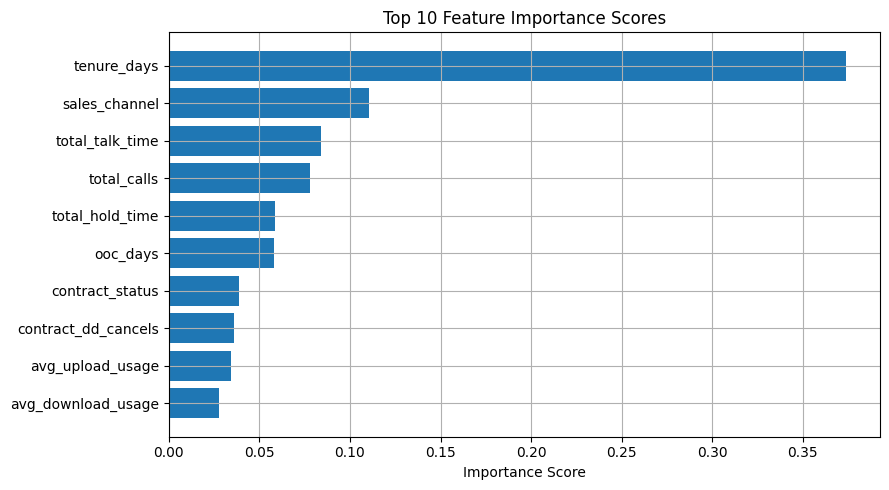

In [58]:

# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nTOP 10 FEATURES")
print(importance_df.head(10))

plt.figure(figsize=(9,5))

plt.barh(
    importance_df["Feature"].head(10)[::-1],
    importance_df["Importance"].head(10)[::-1]
)

plt.xlabel("Importance Score")
plt.title("Top 10 Feature Importance Scores")

plt.grid(True)

plt.tight_layout()

plt.show()


In [59]:

# ============================================================
# CHURN RISK PREDICTIONS
# ============================================================

df["churn_probability"] = model.predict_proba(X)[:, 1]

df["churn_risk"] = np.where(
    df["churn_probability"] >= 0.70,
    "High Risk",
    np.where(
        df["churn_probability"] >= 0.40,
        "Medium Risk",
        "Low Risk"
    )
)

print("\nTOP HIGH-RISK CUSTOMERS")

print(
    df[
        [
            "unique_customer_identifier",
            "churn_probability",
            "churn_risk"
        ]
    ].sort_values(by="churn_probability", ascending=False).head(10)
)



TOP HIGH-RISK CUSTOMERS
                               unique_customer_identifier  churn_probability  \
181180  5524289e20f44e8705447c400919d732f2789f5aeb83d9...           0.980155   
812428  5524289e20f44e8705447c400919d732f2789f5aeb83d9...           0.980155   
238834  c5ba59c716a87ecbf0cf655e77ab19f6379c4d6f447cd7...           0.980056   
226952  8859b9257bc6046a92bafd857d334a9ea2e2dc93c46404...           0.978567   
298286  8f9ddb03aa6d5c4fc8cf2bd7e9a802b047037fc338778c...           0.978160   
837403  1733a0f6487ad80f81e2112b7003a26ba32fd46a6a4da1...           0.977440   
386794  3f3a90de30a2cfd6da4eba8023be8f4f4abf2e08b752d2...           0.977355   
926522  25c4ca11093745551d03876afea5e20416f10224124268...           0.977207   
734264  25c4ca11093745551d03876afea5e20416f10224124268...           0.977207   
959229  a4913c4ed684e50c5d724ba69f68f5da4357bb153f2054...           0.977134   

       churn_risk  
181180  High Risk  
812428  High Risk  
238834  High Risk  
226952  High R

In [60]:

# ============================================================
# EXPORT PREDICTIONS
# ============================================================

df[[
    "unique_customer_identifier",
    "churn_probability",
    "churn_risk"
]].to_csv(
    "customer_churn_predictions.csv",
    index=False
)

print("Prediction file exported successfully.")


Prediction file exported successfully.


In [61]:

# ============================================================
# FINAL BUSINESS INSIGHTS
# ============================================================

print(
    '''

1. Out-of-contract customers show significantly higher churn risk.

2. Long support hold times correlate with customer dissatisfaction.

3. Lower broadband usage may indicate reduced customer engagement.

4. Frequent DD cancellations strongly relate to churn behavior.

5. The model enables proactive customer retention strategies.

6. Random Forest achieved strong churn prediction performance.

'''
)




1. Out-of-contract customers show significantly higher churn risk.

2. Long support hold times correlate with customer dissatisfaction.

3. Lower broadband usage may indicate reduced customer engagement.

4. Frequent DD cancellations strongly relate to churn behavior.

5. The model enables proactive customer retention strategies.

6. Random Forest achieved strong churn prediction performance.


